In [15]:
import pandas as pd
import numpy as np

In [2]:

# Datasets url
url = "https://raw.githubusercontent.com/prasertcbs/basic-dataset/master/cereal.csv"

# Load data
DATA = pd.read_csv(url)


In [3]:
df = DATA.copy()

# Step 1: Dataset Schema , Initial Assessment And Inspection

In [4]:
# Display shape and column details
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Columns:")
print(df.columns.tolist())
print("\nFirst 3 rows:")
print(df.head(3))

Shape: 77 rows, 16 columns

Columns:
['name', 'mfr', 'type', 'calories', 'protein', 'fat', 'sodium', 'fiber', 'carbo', 'sugars', 'potass', 'vitamins', 'shelf', 'weight', 'cups', 'rating']

First 3 rows:
                name mfr type  calories  protein  fat  sodium  fiber  carbo  \
0          100% Bran   N    C        70        4    1     130   10.0    5.0   
1  100% Natural Bran   Q    C       120        3    5      15    2.0    8.0   
2           All-Bran   K    C        70        4    1     260    9.0    7.0   

   sugars  potass  vitamins  shelf  weight  cups     rating  
0       6     280        25      3     1.0  0.33  68.402973  
1       8     135         0      3     1.0  1.00  33.983679  
2       5     320        25      3     1.0  0.33  59.425505  


# Step 2 Data Cleaning

In [10]:
# print(df.isnull().sum())
print("\nCount of -1 values in numeric columns:")
print((df == -1).sum()[lambda x: x > 0])


Count of -1 values in numeric columns:
carbo     1
sugars    1
potass    2
dtype: int64


In [24]:
col_neg = ['carbo','sugars','potass']

In [25]:
for col in col_neg:
    df[col] = df[col].replace(-1,np.nan)

# Mapping

In [27]:
mfr_map = {
    'A': 'American Home Food Products',
    'G': 'General Mills',
    'K': 'Kellogg\'s',
    'N': 'Nabisco',
    'P': 'Post',
    'Q': 'Quaker Oats',
    'R': 'Ralston Purina'
}

In [28]:
df['mfr'] = df['mfr'].map(mfr_map)

In [32]:
df['type'].value_counts()

type
C    74
H     3
Name: count, dtype: int64

In [33]:
df['type'] = df['type'].map({'C':'Cold','H':'Hot'})

C:\Users\Murtaza\AppData\Local\Temp\ipykernel_9156\506829820.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='mfr_full', data=df, order=df['mfr_full'].value_counts().index, ax=axes[1, 1], palette='Blues_r')
C:\Users\Murtaza\AppData\Local\Temp\ipykernel_9156\506829820.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='shelf', data=df, ax=axes[1, 2], palette='pastel')


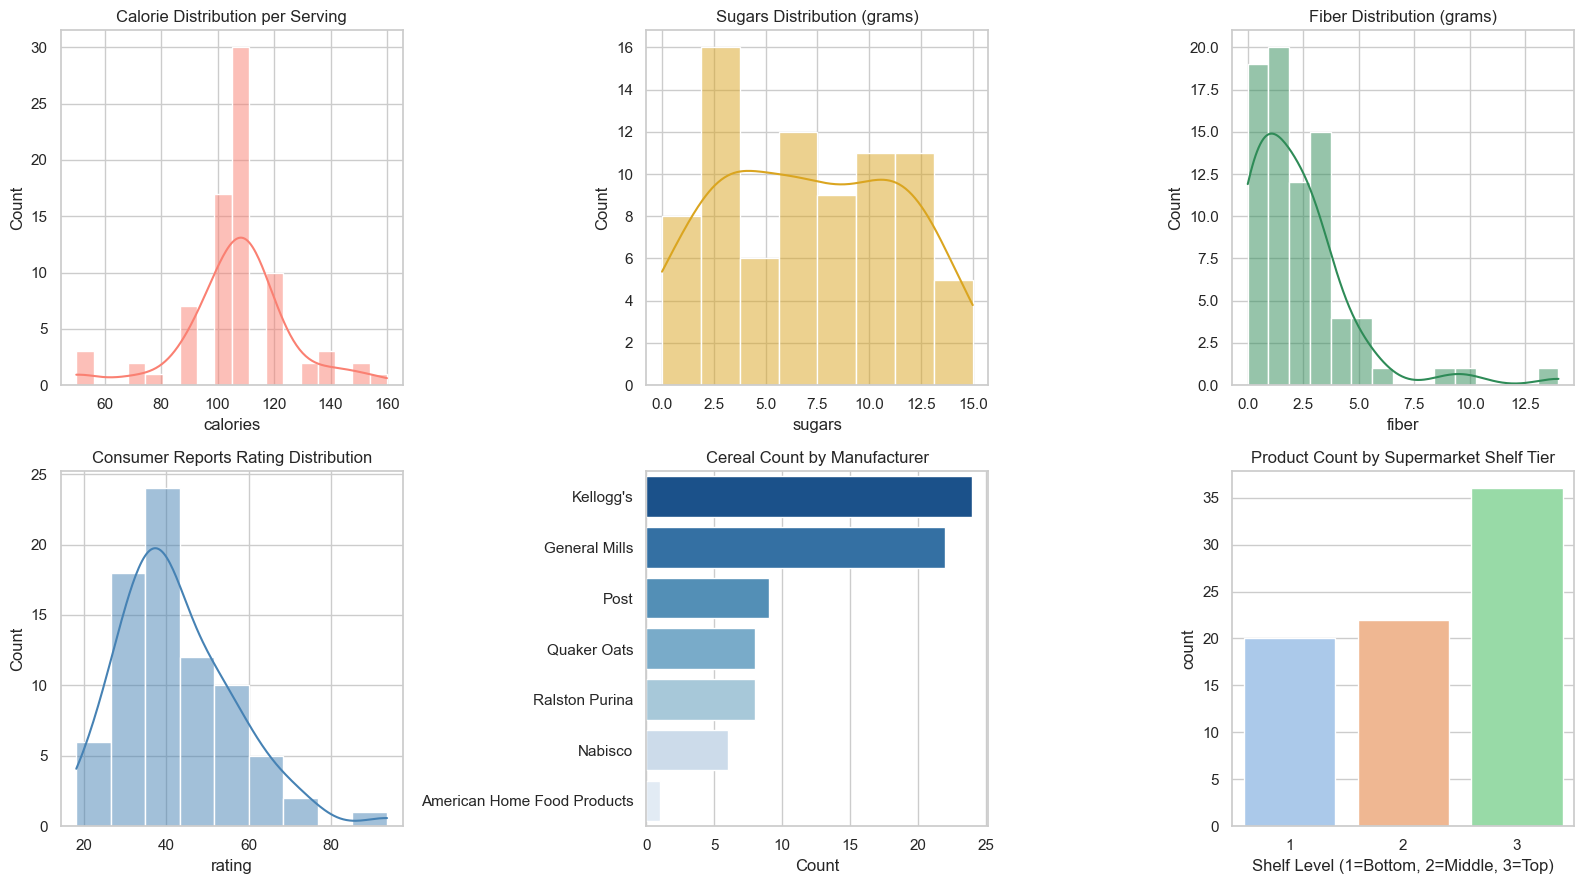

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Calories Distribution
sns.histplot(df['calories'], kde=True, ax=axes[0, 0], color='salmon')
axes[0, 0].set_title('Calorie Distribution per Serving')

# 2. Sugars Distribution
sns.histplot(df['sugars'], kde=True, ax=axes[0, 1], color='goldenrod')
axes[0, 1].set_title('Sugars Distribution (grams)')

# 3. Dietary Fiber Distribution
sns.histplot(df['fiber'], kde=True, ax=axes[0, 2], color='seagreen')
axes[0, 2].set_title('Fiber Distribution (grams)')

# 4. Rating Distribution
sns.histplot(df['rating'], kde=True, ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Consumer Reports Rating Distribution')

# 5. Manufacturer Market Share in Dataset
sns.countplot(y='mfr_full', data=df, order=df['mfr_full'].value_counts().index, ax=axes[1, 1], palette='Blues_r')
axes[1, 1].set_title('Cereal Count by Manufacturer')
axes[1, 1].set_xlabel('Count')
axes[1, 1].set_ylabel('')

# 6. Shelf Placement Count
sns.countplot(x='shelf', data=df, ax=axes[1, 2], palette='pastel')
axes[1, 2].set_title('Product Count by Supermarket Shelf Tier')
axes[1, 2].set_xlabel('Shelf Level (1=Bottom, 2=Middle, 3=Top)')

plt.tight_layout()
plt.savefig('univariate_analysis.png', dpi=300)
plt.show()